In [12]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [16]:
import pickle
import os
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
from google.colab import files

uploaded = files.upload()

Saving cifar-10-python.tar.gz to cifar-10-python.tar.gz


In [6]:
tar_path = next(iter(uploaded.keys()))

print("TAR file path:", tar_path)

TAR file path: cifar-10-python.tar.gz


In [7]:
import os
import tarfile

extract_path = "/content/cifar10_dataset"

os.makedirs(extract_path, exist_ok=True)

with tarfile.open(tar_path, "r:gz") as tar:
    tar.extractall(path=extract_path)

print("Dataset extracted successfully!")

/tmp/ipykernel_791/95399786.py:9: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(path=extract_path)


Dataset extracted successfully!


In [13]:
data_dir = os.path.join(
    extract_path,
    "cifar-10-batches-py"
)

print("Dataset files:")

print(os.listdir(data_dir))

Dataset files:
['data_batch_5', 'readme.html', 'data_batch_1', 'data_batch_2', 'data_batch_3', 'test_batch', 'data_batch_4', 'batches.meta']


In [14]:
def load_batch(file_path):

    with open(file_path, "rb") as f:
        batch = pickle.load(f, encoding="bytes")

    images = batch[b"data"]
    labels = batch[b"labels"]

    images = images.reshape(-1, 3, 32, 32)

    images = images.transpose(0, 2, 3, 1)

    return images, np.array(labels)

In [17]:
X_train_list = []
y_train_list = []

# Load training batches
for i in range(1, 6):

    file_path = os.path.join(
        data_dir,
        f"data_batch_{i}"
    )

    X_batch, y_batch = load_batch(file_path)

    X_train_list.append(X_batch)
    y_train_list.append(y_batch)


# Combine training batches
X_train = np.concatenate(X_train_list)

y_train = np.concatenate(y_train_list)


# Load testing batch
X_test, y_test = load_batch(
    os.path.join(data_dir, "test_batch")
)


# Reshape labels
y_train = y_train.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)


print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000, 1)


In [18]:
class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

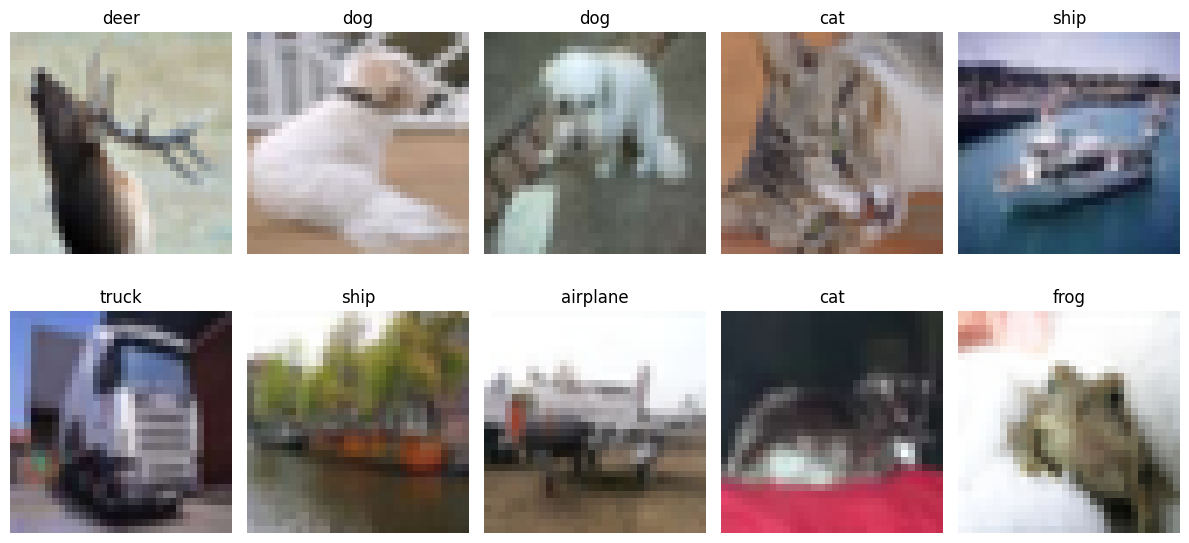

In [19]:
plt.figure(figsize=(12, 6))

indices = np.random.choice(
    len(X_train),
    10,
    replace=False
)

for i, idx in enumerate(indices):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train[idx])

    label = int(y_train[idx][0])

    plt.title(class_names[label])

    plt.axis("off")

plt.tight_layout()
plt.show()

In [20]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.10,
    random_state=42,
    stratify=y_train
)

print("Training:", X_train.shape)
print("Validation:", X_valid.shape)
print("Testing:", X_test.shape)

Training: (45000, 32, 32, 3)
Validation: (5000, 32, 32, 3)
Testing: (10000, 32, 32, 3)


In [21]:
X_train = X_train.astype("float32")
X_valid = X_valid.astype("float32")
X_test = X_test.astype("float32")

mean = np.mean(X_train)
std = np.std(X_train)

X_train = (X_train - mean) / (std + 1e-7)

X_valid = (X_valid - mean) / (std + 1e-7)

X_test = (X_test - mean) / (std + 1e-7)

print("Normalization completed!")

Normalization completed!


In [22]:
y_train_cat = to_categorical(y_train, 10)

y_valid_cat = to_categorical(y_valid, 10)

y_test_cat = to_categorical(y_test, 10)

print("Training labels:", y_train_cat.shape)
print("Validation labels:", y_valid_cat.shape)
print("Testing labels:", y_test_cat.shape)

Training labels: (45000, 10)
Validation labels: (5000, 10)
Testing labels: (10000, 10)


In [23]:
datagen = ImageDataGenerator(

    rotation_range=15,

    width_shift_range=0.12,

    height_shift_range=0.12,

    horizontal_flip=True,

    zoom_range=0.1,

    brightness_range=[0.9, 1.1],

    shear_range=10,

    channel_shift_range=0.1

)

datagen.fit(X_train)

print("Data augmentation configured successfully!")

Data augmentation configured successfully!


In [24]:
weight_decay = 0.0001

model = models.Sequential([

    layers.Input(shape=(32, 32, 3)),

    # BLOCK 1
    layers.Conv2D(32, (3, 3), padding="same",
                  kernel_regularizer=regularizers.l2(weight_decay)),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Conv2D(32, (3, 3), padding="same",
                  kernel_regularizer=regularizers.l2(weight_decay)),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),

    # BLOCK 2
    layers.Conv2D(64, (3, 3), padding="same",
                  kernel_regularizer=regularizers.l2(weight_decay)),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Conv2D(64, (3, 3), padding="same",
                  kernel_regularizer=regularizers.l2(weight_decay)),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    # BLOCK 3
    layers.Conv2D(128, (3, 3), padding="same",
                  kernel_regularizer=regularizers.l2(weight_decay)),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Conv2D(128, (3, 3), padding="same",
                  kernel_regularizer=regularizers.l2(weight_decay)),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.4),

    # BLOCK 4
    layers.Conv2D(256, (3, 3), padding="same",
                  kernel_regularizer=regularizers.l2(weight_decay)),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.Conv2D(256, (3, 3), padding="same",
                  kernel_regularizer=regularizers.l2(weight_decay)),
    layers.BatchNormalization(),
    layers.Activation("relu"),

    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.5),

    # OUTPUT
    layers.Flatten(),
    layers.Dense(10, activation="softmax")

])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 8, 8, 128)      │             

 Total params: 1,186,346 (4.53 MB)

 Trainable params: 1,184,426 (4.52 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [25]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0005
    ),

    loss="categorical_crossentropy",

    metrics=["accuracy"]

)

print("Model compiled successfully!")

Model compiled successfully!


In [26]:
callbacks = [

    tf.keras.callbacks.ModelCheckpoint(
        "best_cifar10_model.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=0.00001,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    )

]

In [27]:
batch_size = 64
epochs = 30

history = model.fit(

    datagen.flow(
        X_train,
        y_train_cat,
        batch_size=batch_size
    ),

    steps_per_epoch=len(X_train) // batch_size,

    epochs=epochs,

    validation_data=(X_valid, y_valid_cat),

    callbacks=callbacks,

    verbose=1

)

Epoch 1/30
703/703 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.2560 - loss: 2.4049
Epoch 1: val_accuracy improved from None to 0.42380, saving model to best_cifar10_model.keras

Epoch 1: finished saving model to best_cifar10_model.keras
703/703 ━━━━━━━━━━━━━━━━━━━━ 732s 1s/step - accuracy: 0.3294 - loss: 2.0088 - val_accuracy: 0.4238 - val_loss: 1.6616 - learning_rate: 5.0000e-04
Epoch 2/30
  1/703 ━━━━━━━━━━━━━━━━━━━━ 10:46 920ms/step - accuracy: 0.4062 - loss: 1.5997

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 2: val_accuracy did not improve from 0.42380
703/703 ━━━━━━━━━━━━━━━━━━━━ 21s 29ms/step - accuracy: 0.4062 - loss: 1.5997 - val_accuracy: 0.4186 - val_loss: 1.6976 - learning_rate: 5.0000e-04
Epoch 3/30
703/703 ━━━━━━━━━━━━━━━━━━━━ 0s 983ms/step - accuracy: 0.4530 - loss: 1.5753
Epoch 3: val_accuracy improved from 0.42380 to 0.53460, saving model to best_cifar10_model.keras

Epoch 3: finished saving model to best_cifar10_model.keras
703/703 ━━━━━━━━━━━━━━━━━━━━ 712s 1s/step - accuracy: 0.4831 - loss: 1.5056 - val_accuracy: 0.5346 - val_loss: 1.4565 - learning_rate: 5.0000e-04
Epoch 4/30
  1/703 ━━━━━━━━━━━━━━━━━━━━ 9:30 812ms/step - accuracy: 0.3906 - loss: 1.7923
Epoch 4: val_accuracy did not improve from 0.53460
703/703 ━━━━━━━━━━━━━━━━━━━━ 21s 29ms/step - accuracy: 0.3906 - loss: 1.7923 - val_accuracy: 0.5326 - val_loss: 1.4452 - learning_rate: 5.0000e-04
Epoch 5/30
703/703 ━━━━━━━━━━━━━━━━━━━━ 0s 976ms/step - accuracy: 0.5486 - loss: 1.3421
Epoch 5: val_accuracy improved fro

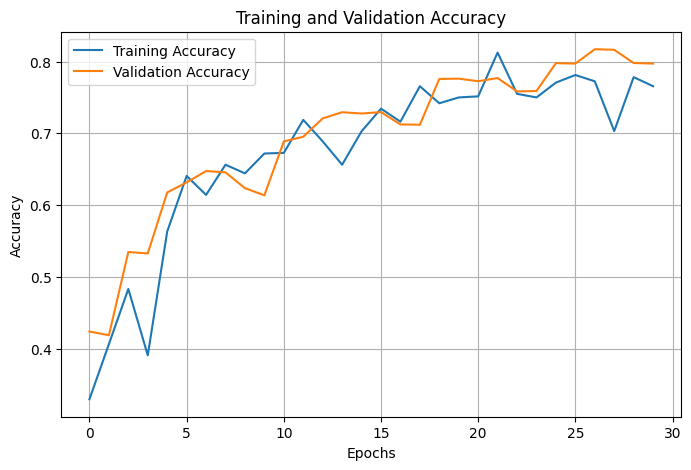

In [28]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")

plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training and Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.show()

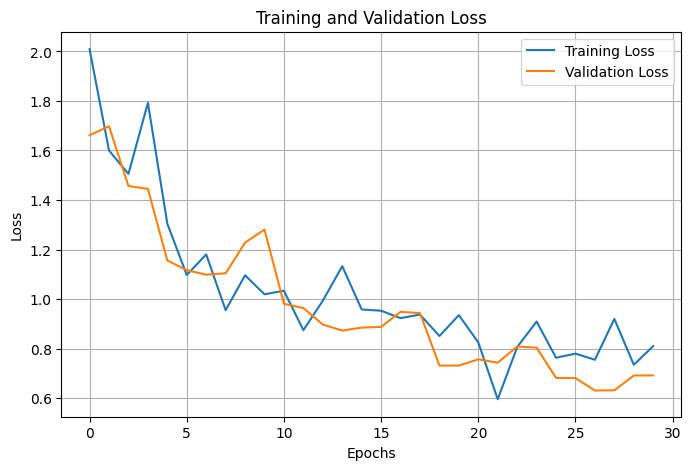

In [29]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")

plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training and Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.show()


In [30]:
best_model = tf.keras.models.load_model(
    "best_cifar10_model.keras"
)

print("Best model loaded successfully!")

Best model loaded successfully!


In [31]:
test_loss, test_accuracy = best_model.evaluate(
    X_test,
    y_test_cat
)

print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 30s 90ms/step - accuracy: 0.8050 - loss: 0.6802
Test Loss: 0.6801676750183105
Test Accuracy: 80.50000071525574 %


In [32]:
y_pred_prob = best_model.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)

y_true = y_test.reshape(-1)

print("Predictions completed!")

313/313 ━━━━━━━━━━━━━━━━━━━━ 36s 113ms/step
Predictions completed!


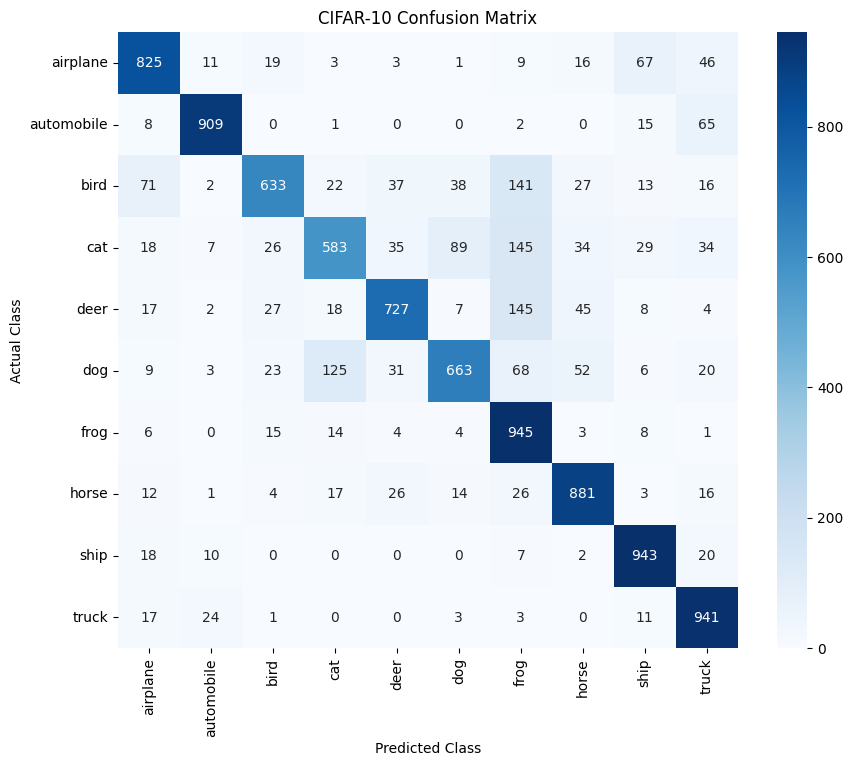

In [33]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title("CIFAR-10 Confusion Matrix")

plt.show()

In [34]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

    airplane       0.82      0.82      0.82      1000
  automobile       0.94      0.91      0.92      1000
        bird       0.85      0.63      0.72      1000
         cat       0.74      0.58      0.65      1000
        deer       0.84      0.73      0.78      1000
         dog       0.81      0.66      0.73      1000
        frog       0.63      0.94      0.76      1000
       horse       0.83      0.88      0.86      1000
        ship       0.85      0.94      0.90      1000
       truck       0.81      0.94      0.87      1000

    accuracy                           0.81     10000
   macro avg       0.81      0.81      0.80     10000
weighted avg       0.81      0.81      0.80     10000



In [35]:
best_model.save("cifar10_final_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [36]:
np.savez(
    "cifar10_preprocessing.npz",
    mean=mean,
    std=std
)

print("Preprocessing values saved!")

Preprocessing values saved!


In [37]:
train_accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

best_epoch = np.argmax(val_accuracy)

print("Final Training Accuracy:",
      train_accuracy[-1] * 100, "%")

print("Final Validation Accuracy:",
      val_accuracy[-1] * 100, "%")

print("Best Validation Accuracy:",
      val_accuracy[best_epoch] * 100, "%")

print("Best Epoch:", best_epoch + 1)

Final Training Accuracy: 76.5625 %
Final Validation Accuracy: 79.72000241279602 %
Best Validation Accuracy: 81.72000050544739 %
Best Epoch: 27


In [38]:
test_loss, test_accuracy = best_model.evaluate(
    X_test,
    y_test_cat,
    verbose=1
)

print("Test Loss:", test_loss)

print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 36s 115ms/step - accuracy: 0.8050 - loss: 0.6802
Test Loss: 0.6801676750183105
Test Accuracy: 80.50000071525574 %


In [39]:
!pip install -q gradio

In [45]:
# Save the loaded trained model with your preferred name
best_model.save("/content/cifir10modal.keras")

print("Model saved successfully!")

# Download the model to your computer
from google.colab import files
files.download("/content/cifir10modal.keras")

Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [46]:
from google.colab import files

uploaded = files.upload()

Saving cifir10modal.keras to cifir10modal (1).keras


In [47]:
import tensorflow as tf

best_model = tf.keras.models.load_model("cifir10modal.keras")

print("CIFAR-10 model loaded successfully!")

CIFAR-10 model loaded successfully!


In [48]:
best_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 8, 8, 128)      │             

 Total params: 3,555,200 (13.56 MB)

 Trainable params: 1,184,426 (4.52 MB)

 Non-trainable params: 1,920 (7.50 KB)

 Optimizer params: 2,368,854 (9.04 MB)

In [41]:
import gradio as gr
from PIL import Image
import numpy as np

print("Gradio version:", gr.__version__)

Gradio version: 6.31.0


In [42]:
def predict_image(image):

    # Convert image to RGB
    image = image.convert("RGB")

    # Keep a copy for display
    display_image = image.copy()

    # Resize image
    image = image.resize((32, 32))

    # Convert image into NumPy array
    img_array = np.array(image).astype("float32")

    # Apply training normalization
    img_array = (img_array - mean) / (std + 1e-7)

    # Add batch dimension
    img_array = np.expand_dims(img_array, axis=0)

    # Predict
    predictions = best_model.predict(
        img_array,
        verbose=0
    )[0]

    # Get class probabilities
    results = {
        class_names[i]: float(predictions[i])
        for i in range(10)
    }

    # Return image and confidence scores
    return display_image, results

In [43]:
app = gr.Interface(

    fn=predict_image,

    inputs=gr.Image(
        type="pil",
        label="Upload an Image"
    ),

    outputs=[
        gr.Image(label="Uploaded Image"),

        gr.Label(
            num_top_classes=10,
            label="Predicted Class and Confidence Scores"
        )
    ],

    title="CIFAR-10 Image Classification",

    description=(
        "Upload an image to classify it into one of "
        "10 CIFAR-10 categories using a trained CNN model."
    )

)

In [44]:
app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://bb2fc831ea898bb40b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
